# HOMEWORK 14

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW14

In this homework you are going to build your first classifier for the CIFAR-10 dataset. This dataset contains 10 different classes and you can learn more about it [here](https://www.cs.toronto.edu/~kriz/cifar.html). This homework consists of the following tasks:
* Dataset inspection
* Building the network
* Training
* Evaluation

At the end, as usual, there will be a couple of questions for you to answer :-)

In [1]:
# # Silent installation or update
#
# import sys
# from packaging.requirements import Requirement
# from importlib.metadata import PackageNotFoundError, version
#
# # Clean cache
# !"{sys.executable}" -m pip cache purge -q
#
# # Force updating
# package_update = [
#     "pip",
#     "scikit-learn",
#     "pandas",
# ]
#
# for package_name in package_update:
#     !"{sys.executable}" -m pip install -U "{package_name}" -q
#
# # Install missing packages
# package_array = [
#     "jinja2",
#     "ipywidgets",
#     "nbformat",
#     "numpy",
#     "matplotlib",
#     "opencv-contrib-python",
#     "torch",
#     "keras",
# ]
#
#
#
# def is_package_satisfied(req_str: str) -> bool:
#     try:
#         req = Requirement(req_str)
#         installed_ver = version(req.name)
#         if req.specifier:
#             return installed_ver in req.specifier
#         return True
#     except PackageNotFoundError:
#         return False
#
#
# for package_name in package_array:
#     if not is_package_satisfied(package_name):
#         !"{sys.executable}" -m pip install "{package_name}" -q


In [2]:
# # Synchronization with remote source
#
# import shutil
# from pathlib import Path
#
# # Input data
# hm_version = 14
#
# # Solution
# git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
# main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"
#
# # upload all files
# current_path = !pwd
# current_path = current_path[0]
# parent_path = !dirname "$current_path"
# parent_path = parent_path[0]
# temp_path = f"{parent_path}/temp"
#
# # Clone data
# !rm -rf "$temp_path"
# !git clone "$git_project_url" "$temp_path"
#
# source = Path(temp_path)
# destination = Path(current_path)
# exclude = {main_file_name, ".git", ".idea"}
#
# for item in source.iterdir():
#     if item.name in exclude:
#         continue
#
#     target = destination / item.name
#     if item.is_dir():
#         shutil.copytree(item, target, dirs_exist_ok=True)
#     else:
#         shutil.copy2(item, target)
#
# # Clean temp folder
# !rm -rf "$temp_path"
#
# # Note. To upload big files to GitHub, execute the next command in the terminal
# # 1. brew install git-lfs
# # 2. git lfs install
# # 3.1. git lfs track "*.safetensors"
# # 3.2. git lfs track "*.bin"

### Step 0: Dataset Inspection

Load the dataset and make a quick inspection.

In [9]:
# Downloading data

import os

# has to be set before keras is imported
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['KERAS_HOME'] = os.path.abspath('resources/data')
import keras
import numpy as np
from pathlib import Path
import apps.reporter as rpt

# Input data
n_images_per_class = 3
rng_seed = 42
folder_name = "resources/data"

# Solution
folder_path = Path(folder_name)
folder_path.mkdir(parents=True, exist_ok=True)

# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(rng_seed)
np.random.seed(rng_seed)

# Load the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
# The labels come as (N, 1) arrays, flatten them to (N,)
y_train, y_test = y_train.flatten(), y_test.flatten()

# analysis image
example_img = x_train[0]

# Mapping from class ID to class name
classes = {0: 'plane', 1: 'car', 2: 'bird', 3: 'cat', 4: 'deer', 5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'}

# preparing set of images for showing
preview_samples = []
for class_id in range(len(classes)):
    # filter indexes of the necessary class
    class_indices = np.where(y_train == class_id)[0]
    # get 3 random images
    random_indices = np.random.choice(class_indices, size=n_images_per_class, replace=False)
    # add images to list
    for idx in random_indices:
        preview_samples.append((classes[class_id], x_train[idx]))

rp = rpt.Reporter()
rp.add_item("Dataset directory", folder_name)
rp.add_item("Image: (rows, cols, channels)", str(example_img.shape))
rp.add_item("Pixel value range", f"[{x_train.min()}, {x_train.max()}] ({x_train.dtype})")
rp.add_item("Number of items in the train dataset", f"{len(y_train)} samples")
rp.add_item("Number of items in the test dataset", f"{len(y_test)} samples")
rp.add_item("Count of classes", str(len(classes)))
for key, value in classes.items():
    rp.add_item(f"Class: {value}", f"id: {key}")

# Print results
rp.print_pd_report("Report of CIFAR-10 Dataset Inspection")


Attribute,Result
Dataset directory,resources/data
"Image: (rows, cols, channels)","(32, 32, 3)"
Pixel value range,"[0, 255] (uint8)"
Number of items in the train dataset,50000 samples
Number of items in the test dataset,10000 samples
Count of classes,10
Class: plane,id: 0
Class: car,id: 1
Class: bird,id: 2
Class: cat,id: 3


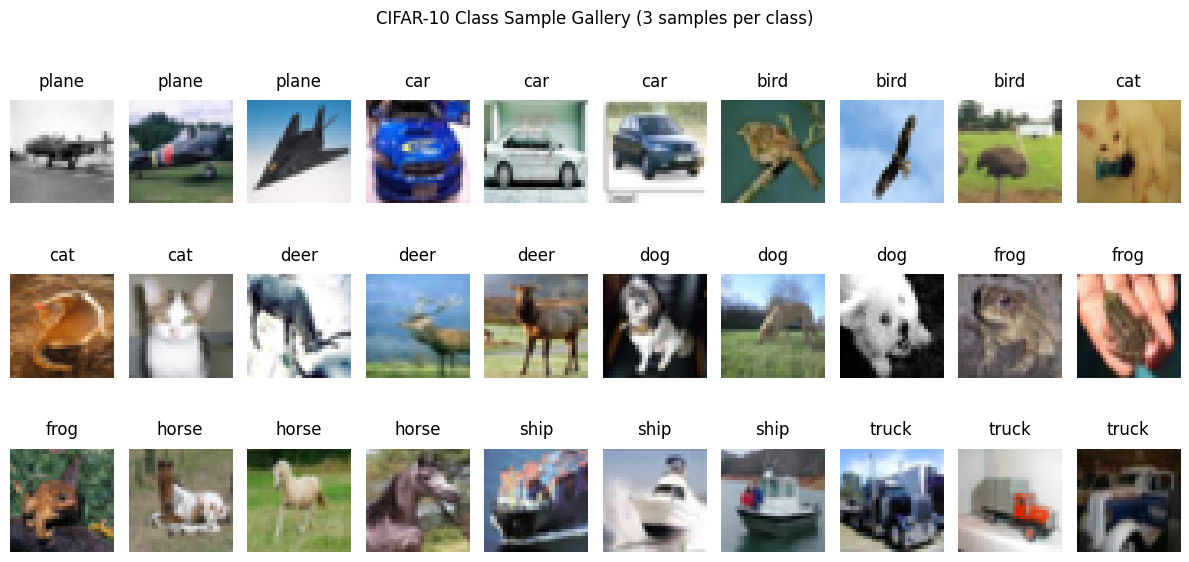

In [4]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 10
images_dict = preview_samples
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 2 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("CIFAR-10 Class Sample Gallery (3 samples per class)", y=1.0)
plt.tight_layout()
plt.show()


Compute the class histogram (you can visualize it if you want). Is the dataset balanced?

Hint: You might find [Counter](https://docs.python.org/3/library/collections.html#collections.Counter) tool useful. In any case, it's up to you how you compute the histogram.

In [5]:
# Compute the class histogram

import numpy as np
import apps.reporter as rpt

# Input data

# Solution
class_names = list(classes.values())

# calculate count of each classes
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)

# check balancing
is_train_balanced = len(set(train_counts)) == 1
is_test_balanced = len(set(test_counts)) == 1

rp = rpt.Reporter()
rp.add_item("Is Train dataset balanced?", 'Yes' if is_train_balanced else 'No')
rp.add_item("Is Test dataset balanced?", 'Yes' if is_test_balanced else 'No')

# Print results
rp.print_pd_report("Report of CIFAR-10 Class Balance")

Attribute,Result
Is Train dataset balanced?,Yes
Is Test dataset balanced?,Yes


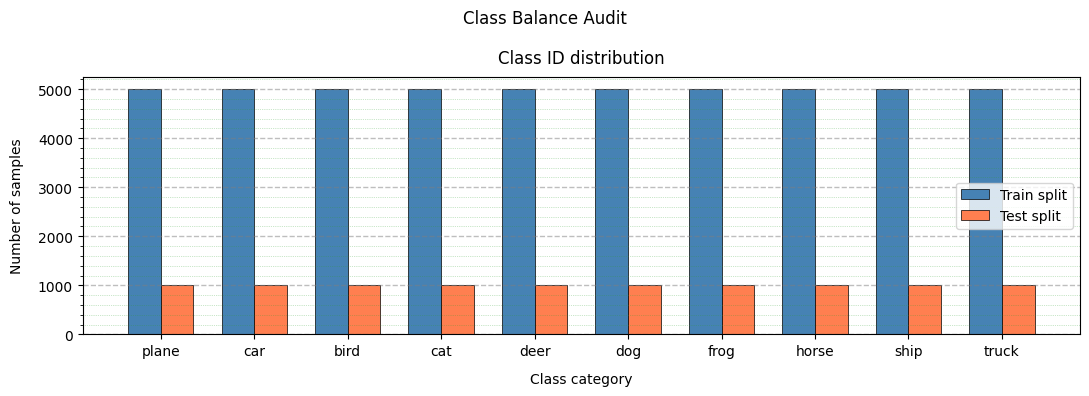

In [6]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
x_indices = np.arange(len(class_names))
bar_width = 0.35

# Solution
_, ax = plt.subplots(figsize=(11, 4))

ax.bar(x_indices - bar_width / 2, train_counts, bar_width,
       label='Train split', color='steelblue', edgecolor='black', linewidth=0.5)
ax.bar(x_indices + bar_width / 2, test_counts, bar_width,
       label='Test split', color='coral', edgecolor='black', linewidth=0.5)

ax.set_xticks(x_indices)
ax.set_xticklabels(class_names, rotation=0, ha='center')
ax.tick_params(axis='x', which='minor', bottom=False, top=False)

ax.grid(axis='y', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
ax.minorticks_on()
ax.grid(axis='y', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Class ID distribution", pad=10, loc='center', color='black')
ax.set_xlabel("Class category", labelpad=10, loc='center', color='black')
ax.set_ylabel("Number of samples", labelpad=10, loc='center', color='black')

ax.legend(frameon=True, loc='center right')
plt.suptitle("Class Balance Audit")

plt.tight_layout()
plt.show()


### Step 1: Data Preparation

In this step, you'll need to prepare the data for training, i.e., you will have to normalize it and encode the labels as one-hot vectors.

In [7]:
# Normalization & One-hot encoding

from sklearn.preprocessing import StandardScaler

# Input data
num_samples_train, height, width, channels = x_train.shape
num_samples_test = x_test.shape[0]

# Solution
scaler = StandardScaler()

# flatten
x_train_flat = x_train.reshape(num_samples_train, -1)
x_test_flat = x_test.reshape(num_samples_test, -1)

# scaling
x_train_flat = scaler.fit_transform(x_train_flat)
x_test_flat = scaler.transform(x_test_flat)

# reshape
x_train_sc = x_train_flat.reshape(num_samples_train, height, width, channels)
x_test_sc = x_test_flat.reshape(num_samples_test, height, width, channels)

# One-hot encoding
y_train_ohe = keras.utils.to_categorical(y_train, num_classes=len(class_names))
y_test_ohe = keras.utils.to_categorical(y_test, num_classes=len(class_names))

rp = rpt.Reporter()
rp.add_item("Train set", f"{len(y_train)} samples")
rp.add_item("Train sample dims", str(x_train_sc.shape))
rp.add_item("Train label dims", str(y_train_ohe.shape))
rp.add_item("Train pixel range", f"[{x_train_sc.min():.1f}, {x_train_sc.max():.1f}], dtype: {x_train_sc.dtype}")
rp.add_item("Test set", f"{len(y_test)} samples")
rp.add_item("Test sample dims", str(x_test_sc.shape))
rp.add_item("Test label dims", str(y_test_ohe.shape))
rp.add_item("Test pixel range", f"[{x_test_sc.min():.1f}, {x_test_sc.max():.1f}], dtype: {x_test_sc.dtype}")

# Print results
rp.print_pd_report("Report of data prepareation")

Attribute,Result
Train set,50000 samples
Train sample dims,"(50000, 32, 32, 3)"
Train label dims,"(50000, 10)"
Train pixel range,"[-2.2, 2.6], dtype: float64"
Test set,10000 samples
Test sample dims,"(10000, 32, 32, 3)"
Test label dims,"(10000, 10)"
Test pixel range,"[-2.2, 2.6], dtype: float64"


### Step 2: Building the Classifier

Build the CNN for CIFAR10 classification. For starters, you can use the same network we used in the lesson for the MNIST problem.

Note that, unlike MNIST, the CIFAR-10 images are color (RGB) images.

In [8]:
# Build the classifier
model =

# Show the model
model.summary()

SyntaxError: invalid syntax (908294618.py, line 2)

### Step 3: Training

Compile the model and train it.

In [ ]:
epochs = 25
batch_size = 128

# Compile the model

# Train the model
history =

In [ ]:
# Show training history (this cell is complete, nothing to implement here :-) )
h = history.history
epochs = range(len(h['loss']))

plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
plt.legend(['Train', 'Validation'])
plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                           epochs, h['val_accuracy'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

print('Train Acc     ', h['accuracy'][-1])
print('Validation Acc', h['val_accuracy'][-1])

### Step 4: Evaluation

In this step, you have to calculate the accuracies and visualize some random samples. For the evaluation, you are going to use the test split from the dataset.

In [ ]:
# Compute the labels and the predictions as sparse values
y_true =
y_pred =

In [ ]:
# Compute and print the accuracy for each class
for class_id, class_name in classes.items():
    acc =
    print(class_name, acc)

In [ ]:
# Print the overall stats
ev = model.evaluate(x_test, y_test)
print('Test loss  ', ev[0])
print('Test metric', ev[1])

In [ ]:
# Show random samples
for ii in range(15):
    # Pick a random sample
    idx =
    # Show the results
    plt.subplot(3, 5, ii + 1), plt.imshow(x_test[idx, ...])
    plt.title('True: ' + str(classes[y_true[idx]]) + ' | Pred: ' + str(classes[y_pred[idx]]))

### Questions
* What is the overall accuracy of the classifier?
* What modifications would you do in order to improve the classification accuracy?
* Make **one** modification (that you think can help) and train the classifier again. Does the accuracy improve?
* Compare the training and the validation accuracy. What do you observe?